# 🕸️ Sesión 1: El ADN de las Redes
Representación de Grafos: Matriz vs Lista de Adyacencia.

## 📐 Formalización Matemática: ¿Qué es un Grafo?

Un grafo es una estructura matemática que modela relaciones entre objetos. Formalmente se define como un par ordenado:

$$G = (V, E)$$

Donde:
*   **$V$ (Vértices / Nodos):** Es el conjunto de entidades que conforman la red. En nuestro ejemplo del pizarrón, $V = \{\text{Ana, Carlos, Luis, Beti}\}$.
*   **$E$ (Aristas / Edges):** Es el conjunto de conexiones (pares de vértices). Si Ana sigue a Carlos, existe una arista $e = (Ana, Carlos)$.

---
### Tipos de Relaciones

1.  **Grafo Dirigido (DiGraph):** Las aristas tienen dirección (flechas). Si $(u, v) \in E$, no implica necesariamente que $(v, u) \in E$. *(Ejemplo: Seguir a alguien en Instagram, transferencias bancarias).* 
2.  **Grafo No Dirigido (Graph):** Las relaciones son recíprocas. La arista $(u, v)$ es idéntica a $(v, u)$. *(Ejemplo: Ser amigos en Facebook, conexiones Bluetooth).* 
3.  **Grafo Ponderado (Weighted Graph):** Cada arista tiene un peso o costo numérico $w(u,v)$. *(Ejemplo: La distancia en kilómetros entre dos aeropuertos, la cantidad de mensajes entre dos usuarios).*

In [3]:
import pandas as pd
import numpy as np

df_vuelos = pd.read_csv('./vuelos10k.csv')
print("Registros iniciales:", len(df_vuelos))   # 10,000
display(df_vuelos.head())

# 1. Valores nulos: sin Origen o Destino no hay ruta
print("\nNulos por columna:\n", df_vuelos.isna().sum())
df_vuelos = df_vuelos.dropna(subset=['Origen', 'Destino'])
print("Tras eliminar nulos:", len(df_vuelos))   # 9,849 (-151)

# 2. Formato inconsistente: todo a 3 letras MAYÚSCULAS
minusculas = (~df_vuelos['Origen'].str.isupper() | ~df_vuelos['Destino'].str.isupper()).sum()
print("\nFilas con minúsculas:", minusculas)   # 800
df_vuelos['Origen'] = df_vuelos['Origen'].str.strip().str.upper()
df_vuelos['Destino'] = df_vuelos['Destino'].str.strip().str.upper()

# 3. Self-loops: mismo origen y destino → se eliminan
self_loops = (df_vuelos['Origen'] == df_vuelos['Destino']).sum()
print("Self-loops encontrados:", self_loops)   # 105
df_vuelos = df_vuelos[df_vuelos['Origen'] != df_vuelos['Destino']]

# 4. Distancias negativas: error de captura del signo → valor absoluto
negativos = (df_vuelos['Distancia_km'] < 0).sum()
print("Distancias negativas:", negativos)   # 100
df_vuelos['Distancia_km'] = df_vuelos['Distancia_km'].abs()

# 5. Duplicados: misma ruta (Origen, Destino)
duplicados = df_vuelos.duplicated(subset=['Origen', 'Destino']).sum()
print("Rutas duplicadas:", duplicados)   # 1
df_vuelos = df_vuelos.drop_duplicates(subset=['Origen', 'Destino']).reset_index(drop=True)

print("\nRegistros finales limpios:", len(df_vuelos))   # 9,743
display(df_vuelos.describe())

Registros iniciales: 10000


,Origen,Destino,Distancia_km
0,RYI,KXK,965.34
1,ULE,PVC,1098.58
2,LTV,MOV,2713.63
3,NFR,CLR,1138.99
4,TSF,CZE,1691.08



Nulos por columna:
 Origen           51
Destino         100
Distancia_km      0
dtype: int64
Tras eliminar nulos: 9849

Filas con minúsculas: 800
Self-loops encontrados: 105
Distancias negativas: 100
Rutas duplicadas: 1

Registros finales limpios: 9743


,Distancia_km
count,9743.000000
mean,1516.650683
std,763.619223
min,0.040000
25%,964.520000
50%,1496.380000
75%,2034.255000
max,4818.320000


**¿Qué debemos hacer con los Self-Loops?**
Eliminarlos. Un vuelo que sale y llega al mismo aeropuerto no representa una ruta real, es un error de captura. En el grafo aparecería como una arista que apunta al mismo nodo, lo que inflaría artificialmente las conexiones del aeropuerto y no aporta información sobre la red. Se encontraron y eliminaron 105.

In [5]:
import networkx as nx

G = nx.from_pandas_edgelist(
    df_vuelos,
    source='Origen',
    target='Destino',
    edge_attr='Distancia_km',
    create_using=nx.DiGraph()
)

print(f"Nodos (Aeropuertos): {G.number_of_nodes()}")   # 3,253
print(f"Aristas (Rutas):     {G.number_of_edges()}")   # 9,743

Nodos (Aeropuertos): 3253
Aristas (Rutas):     9743


### ⚠️ El colapso en la RAM: La Matriz de Adyacencia
Fácil de leer para las matemáticas, terrible para la memoria de la computadora en Big Data.

In [6]:
# 1. Matriz de Adyacencia densa
matriz_densa = nx.adjacency_matrix(G).todense()
print("Dimensiones de la matriz:", matriz_densa.shape)   # (3253, 3253)
print(f"Celdas en cero: {(matriz_densa == 0).mean() * 100:.2f}%")   # 99.91%

# 2. RAM de la matriz
mb_matriz = matriz_densa.nbytes / 1024**2
print(f"\nRAM Matriz de Adyacencia: {mb_matriz:.2f} MB")   # ≈ 80.73 MB

# 3. RAM de la lista de aristas (deep=True cuenta también el peso real de los textos)
mb_lista = df_vuelos.memory_usage(deep=True).sum() / 1024**2
print(f"RAM Lista de Aristas:     {mb_lista:.2f} MB")   # ≈ 1.04 MB

# 4. Comparación
veces = mb_matriz / mb_lista
print(f"\nLa matriz es {veces:.0f} veces más pesada que la lista de aristas")   # ≈ 78

Dimensiones de la matriz: (3253, 3253)
Celdas en cero: 99.91%

RAM Matriz de Adyacencia: 80.73 MB
RAM Lista de Aristas:     1.19 MB

La matriz es 68 veces más pesada que la lista de aristas


/var/folders/f1/kgxxq9n5397_xl_0y50ngfxm0000gn/T/ipykernel_14655/1846566486.py:2: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  matriz_densa = nx.adjacency_matrix(G).todense()


## Veredicto

La Matriz de Adyacencia ocupa **≈ 80.7 MB**, mientras que la Lista de Aristas ocupa **≈ 1.04 MB**: la matriz es **≈ 78 veces más pesada**.

**¿Por qué?**
- La matriz guarda todas las combinaciones posibles de aeropuertos: 3,253 × 3,253 = **10.6 millones de celdas**. Su tamaño crece con el **cuadrado** del número de nodos.
- Solo existen **9,743 rutas**, así que el **99.91% de la matriz son ceros**: memoria gastada en guardar "aquí no hay vuelo".
- La Lista de Aristas solo guarda las rutas que **sí existen**, así que crece con el número de aristas, O(E).

Las redes reales son **dispersas** (sparse): cada aeropuerto conecta con unos pocos, no con todos. Si la red creciera a 40,000 aeropuertos, la matriz necesitaría más RAM y colapsaría el equipo, mientras que la lista seguiría pesando unos pocos MB.

### 🚀 La Salvación: Lista de Aristas (Edge List)
Solo guardamos las conexiones que SÍ existen.

Hub principal: BLZ con 16 rutas


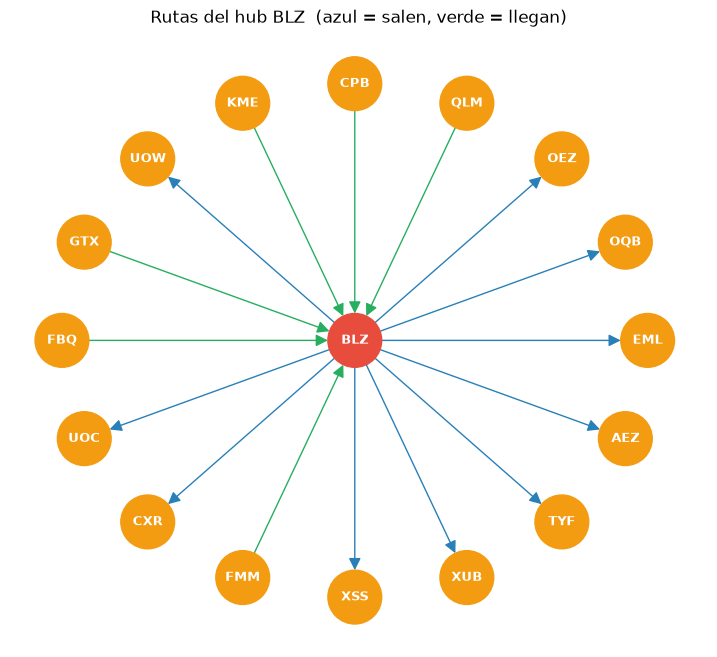

In [7]:
import matplotlib.pyplot as plt

# Aeropuerto con más conexiones (entradas + salidas)
grados = dict(G.degree())
hub = max(grados, key=grados.get)
print(f"Hub principal: {hub} con {grados[hub]} rutas")

# Subgrafo: el hub + sus vecinos directos
sub = nx.ego_graph(G, hub, radius=1, undirected=True)
vecinos = [n for n in sub.nodes() if n != hub]
salidas  = [(u, v) for u, v in sub.edges() if u == hub]
llegadas = [(u, v) for u, v in sub.edges() if v == hub]

plt.figure(figsize=(9, 8))
pos = nx.shell_layout(sub, nlist=[[hub], vecinos])   # hub al centro, vecinos en círculo
colores = ['#E74C3C' if n == hub else '#F39C12' for n in sub.nodes()]

nx.draw_networkx_nodes(sub, pos, node_color=colores, node_size=1500)
nx.draw_networkx_labels(sub, pos, font_size=9, font_weight='bold', font_color='white')
nx.draw_networkx_edges(sub, pos, edgelist=salidas,  edge_color='#2980B9', arrowsize=18, node_size=1500)
nx.draw_networkx_edges(sub, pos, edgelist=llegadas, edge_color='#27AE60', arrowsize=18, node_size=1500)

plt.title(f'Rutas del hub {hub}  (azul = salen, verde = llegan)')
plt.axis('off')
plt.show()